# ML Fundamentals: Linear Regression

Hands-on exercises with **scikit-learn** on synthetic data — no real dataset needed.

| Exercise | Topic |
|---|---|
| 1 | Fitting a simple linear regression and reading coefficients |
| 2 | Train/test split and evaluating on held-out data |
| 3 | Evaluation metrics: MAE, MSE, RMSE and R² |
| 4 | Multicollinearity (VIF) |
| 5 | Multiple linear regression and feature importance |
| 6–7 | Two-feature regression on a 3D surface |
| 8 | Residual plot |
| 9 | Overfitting: 30 samples, 40 features |
| 10 | Ridge regularisation |
| 11 | Lasso regularisation and automatic feature selection |
| 12 | Comparing plain, Ridge and Lasso test errors |

**Libraries:** NumPy, Pandas, Matplotlib, scikit-learn, statsmodels

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

## Exercise 1 — Simple linear regression

**Task:** Generate 100 synthetic observations for X (uniform in [0, 2]) with the true relationship
`y = 4 + 3X + noise`. Fit a linear model and read its slope and intercept.

In [2]:
np.random.seed(42)

# Generate 100 random values for X (range 0 to 2)
X = 2 * np.random.rand(100, 1)
noise = np.random.randn(100, 1)
y = 4 + 3 * X + noise

model = LinearRegression()
model.fit(X, y)

slope = model.coef_[0][0]
intercept = model.intercept_[0]

print(f"Fitted slope (a):     {slope:.4f}")
print(f"Fitted intercept (b): {intercept:.4f}")

Fitted slope (a):     2.7701
Fitted intercept (b): 4.2151


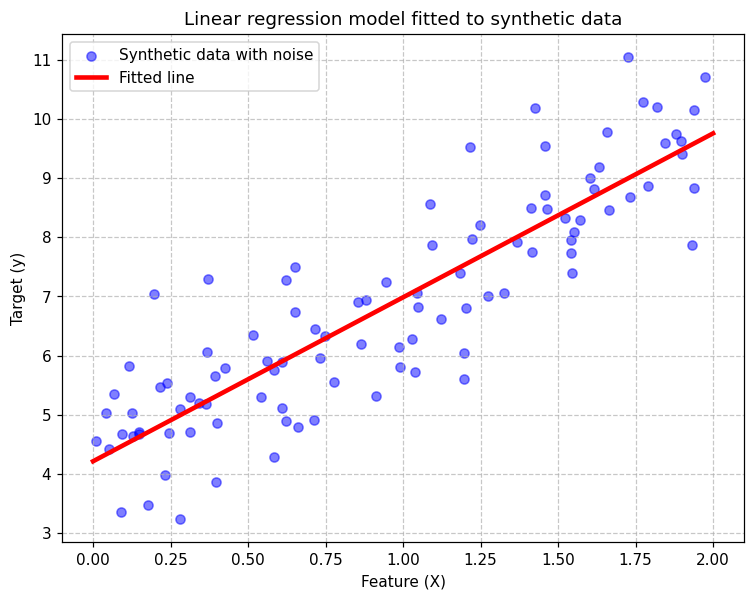

In [3]:
# Create two extreme x-values to draw the fitted line
X_plot = np.array([[0], [2]])
y_pred_plot = model.predict(X_plot)

plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Synthetic data with noise')
plt.plot(X_plot, y_pred_plot, color='red', linewidth=3, label='Fitted line')
plt.title('Linear regression model fitted to synthetic data')
plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Exercise 2 — Train/test split

**Task:** Rebuild the dataset with 250 observations, split 80/20, fit the model on the training
set and evaluate it on the test set.

In [4]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
X = 2 * np.random.rand(250, 1)
noise = np.random.randn(250, 1)
y = 4 + 3 * X + noise

# test_size=0.2 → 20% held out for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Test samples:     {len(X_test)}")

Training samples: 200
Test samples:     50


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

# MSE: lower is better; R²: 1.0 is perfect
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Coefficient of Determination (R²): {r2:.4f}")

Mean Squared Error (MSE): 0.9659
Coefficient of Determination (R²): 0.7346


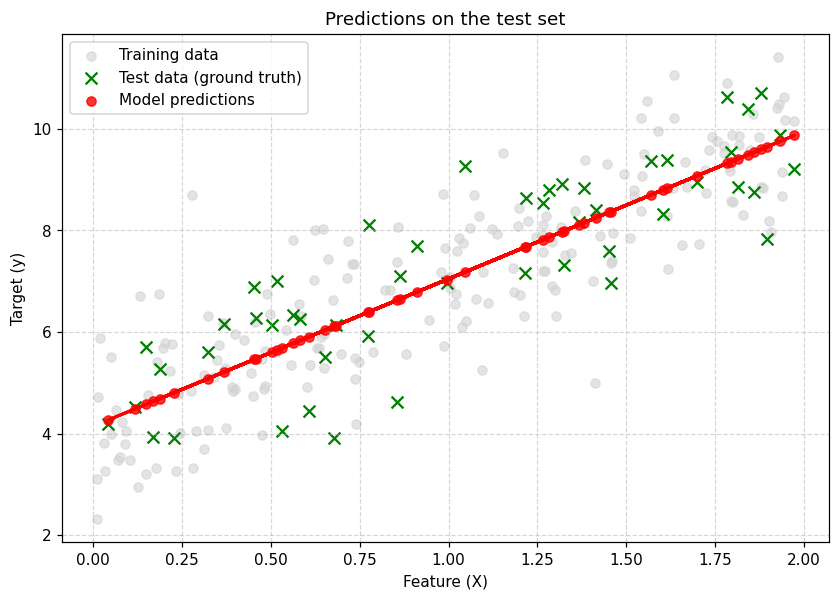

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(X_train, y_train, color='lightgray', alpha=0.6, label='Training data')
plt.scatter(X_test, y_test, color='green', marker='x', s=60, label='Test data (ground truth)')
plt.scatter(X_test, y_pred, color='red', alpha=0.8, label="Model predictions")
plt.plot(X_test, y_pred, color='red', linewidth=2)

plt.title('Predictions on the test set')
plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Exercise 3 — Evaluation metrics

**Task:** Implement a helper that computes MAE, MSE, RMSE and R².
Run it first on clean data and then on a dataset with one large outlier to see how sensitive each metric is.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_actual, y_prediction):
    mae  = mean_absolute_error(y_actual, y_prediction)
    mse  = mean_squared_error(y_actual, y_prediction)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_actual, y_prediction)

    print(f"MAE  (Mean Absolute Error):          {mae:.2f}")
    print(f"MSE  (Mean Squared Error):           {mse:.2f}")
    print(f"RMSE (Root Mean Squared Error):      {rmse:.2f}")
    print(f"R²   (Coefficient of Determination): {r2:.4f}")

In [9]:
# Clean data — 4 observations
y_actual = np.array([3.0, -0.5, 2.0, 7.0])
y_pred_clean = np.array([2.5, 0.0, 2.0, 8.0])

print("--- RESULTS FOR CLEAN DATA ---")
evaluate_model(y_actual, y_pred_clean)

--- RESULTS FOR CLEAN DATA ---
MAE  (Mean Absolute Error):          0.50
MSE  (Mean Squared Error):           0.38
RMSE (Root Mean Squared Error):      0.61
R²   (Coefficient of Determination): 0.9486


In [10]:
# Add one large outlier: true value 100, predicted value 10
y_with_outlier  = np.array([3.0, -0.5, 2.0, 7.0, 100.0])
y_pred_outlier  = np.array([2.5, 0.0,  2.0, 8.0,  10.0])

print("--- RESULTS WITH OUTLIER ---")
evaluate_model(y_with_outlier, y_pred_outlier)

--- RESULTS WITH OUTLIER ---
MAE  (Mean Absolute Error):          18.40
MSE  (Mean Squared Error):           1620.30
RMSE (Root Mean Squared Error):      40.25
R²   (Coefficient of Determination): -0.0694


## Exercise 4 — Multicollinearity (VIF)

**Task:** Generate flat data (area in m² and the same area converted to ft²) alongside two
genuinely independent features and check which ones cause multicollinearity using the
Variance Inflation Factor (VIF > 10 is a warning sign).

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(42)
# 100 synthetic flats
area_m2   = np.random.randint(30, 150, 100)
num_rooms = np.random.randint(1, 5, 100)
distance  = np.random.uniform(1, 15, 100)
# 1 m² ≈ 10.76 ft² — add a tiny noise so the matrix is not perfectly singular
area_ft2  = area_m2 * 10.76 + np.random.normal(0, 5, 100)

data = pd.DataFrame({
    'Area_m2':   area_m2,
    'Num_rooms': num_rooms,
    'Distance':  distance,
    'Area_ft2':  area_ft2,
})

def compute_vif(df):
    result = pd.DataFrame()
    result["Feature"] = df.columns
    result["VIF"] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return result

print("--- Multicollinearity test (VIF) ---")
print(compute_vif(data).to_string(index=False))

--- Multicollinearity test (VIF) ---
         Feature           VIF
        Area_m2  39017.110749
       Num_rooms      4.206418
        Distance      3.984060
        Area_ft2  39070.451950


> **Interpretation:** `Area_m2` and `Area_ft2` have astronomically high VIF values, confirming that they carry the same information. Drop one of them before fitting a regression model.

## Exercise 5 — Multiple linear regression and feature importance

**Task:** Generate 300 observations with three features where the true weights are
+30, −15 and ~0. Fit a multiple regression and recover the weights — the model should
identify which feature is important and which is noise.

In [12]:
np.random.seed(42)

X1 = np.random.rand(300, 1)
X2 = np.random.rand(300, 1)
X3 = np.random.rand(300, 1)

# X1 has a large positive effect, X2 a strong negative one, X3 almost none
X = np.hstack([X1, X2, X3])
noise = np.random.randn(300, 1)
y = 50 + 30 * X1 - 15 * X2 + 0.5 * X3 + noise

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

weights = model.coef_.flatten()

feature_analysis = pd.DataFrame({
    'Feature': ['Feature 1 (Study time)', 'Feature 2 (Gaming hours)', 'Feature 3 (Apples eaten)'],
    'Fitted weight': weights,
})

feature_analysis['Absolute influence'] = feature_analysis['Fitted weight'].abs()
feature_analysis = feature_analysis.sort_values(by='Absolute influence', ascending=False)

print("--- FEATURE IMPORTANCE ---")
print(feature_analysis.drop(columns=['Absolute influence']).to_string(index=False))

--- FEATURE IMPORTANCE ---
                     Feature  Fitted weight
      Feature 1 (Study time)      30.005888
 Feature 2 (Gaming hours)        -14.869487
   Feature 3 (Apples eaten)        0.794932


In [13]:
y_pred = model.predict(X_test)
r2  = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("--- TEST SET RESULTS ---")
print(f"R² (model accuracy): {r2:.4f}")
print(f"MSE (model error):   {mse:.4f}")

--- TEST SET RESULTS ---
R² (model accuracy): 0.9879
MSE (model error):   1.1327


## Exercises 6–7 — Two-feature regression on a 3D surface

**Task:** Generate 200 observations with two features using the true relationship
`y = 5·X1 − 3·X2 + 10`. Fit a multiple regression, then visualise the fitted plane in 3D.

In [14]:
np.random.seed(42)

X1 = 10 * np.random.rand(200, 1)
X2 =  5 * np.random.rand(200, 1)
X  = np.hstack([X1, X2])

noise = np.random.rand(200, 1)
y = 5 * X1 - 3 * X2 + 10 + noise

model = LinearRegression()
model.fit(X, y)
print("Intercept:", round(model.intercept_[0], 4),
      " Coefficients:", [round(c, 4) for c in model.coef_[0]])

Intercept: 10.6119  Coefficients: [np.float64(4.9948), np.float64(-3.0263)]


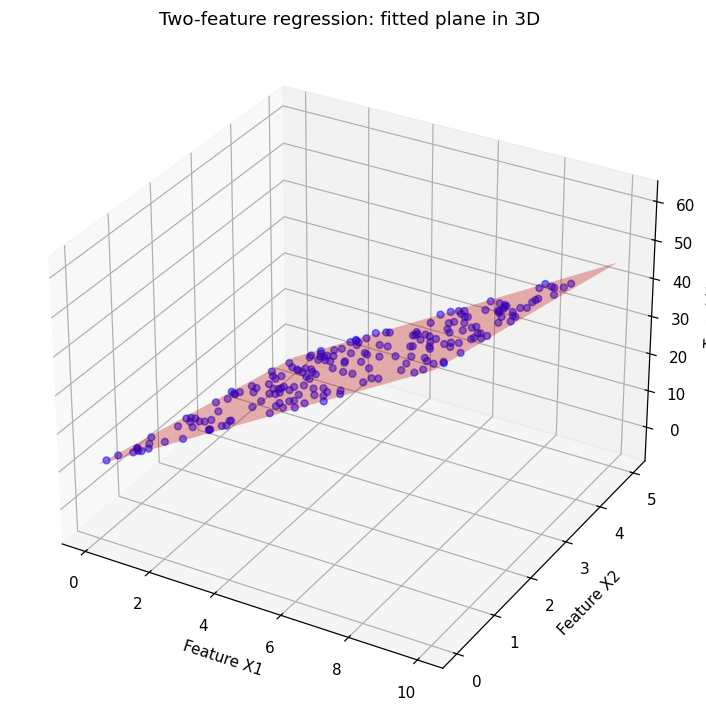

In [15]:
fig = plt.figure(figsize=(10, 8))
ax  = fig.add_subplot(projection='3d')

# True data points
ax.scatter(X1, X2, y, color='blue', alpha=0.5, label='True data')

# Mesh grid to draw the fitted plane
x1_mesh, x2_mesh = np.meshgrid(np.linspace(0, 10, 10), np.linspace(0, 5, 10))
y_mesh = model.intercept_[0] + model.coef_[0][0] * x1_mesh + model.coef_[0][1] * x2_mesh

ax.plot_surface(x1_mesh, x2_mesh, y_mesh, color='red', alpha=0.3)

ax.set_xlabel('Feature X1')
ax.set_ylabel('Feature X2')
ax.set_zlabel('Target Y')
plt.title('Two-feature regression: fitted plane in 3D')
plt.show()

## Exercise 8 — Residual plot

**Task:** Plot the residuals (y_actual − y_predicted) against the predicted values.
Randomly scattered residuals around zero indicate that the model's assumptions hold.

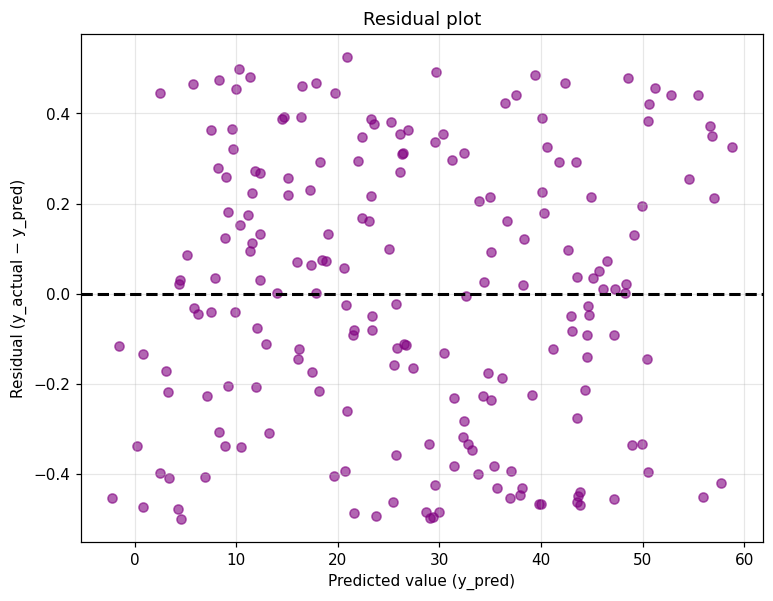

In [16]:
y_pred_all = model.predict(X)
residuals  = y - y_pred_all

plt.figure(figsize=(8, 6))
plt.scatter(y_pred_all, residuals, color='purple', alpha=0.6)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.title('Residual plot')
plt.xlabel('Predicted value (y_pred)')
plt.ylabel('Residual (y_actual − y_pred)')
plt.grid(True, alpha=0.3)
plt.show()

## Exercise 9 — Overfitting: 30 samples, 40 features

**Task:** Demonstrate overfitting by fitting a standard linear regression on a dataset
with far more features than samples.  
Training error should be ~0; test error should be very large.

In [17]:
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler

# 30 observations, 40 features, only 3 are actually informative
X, y = make_regression(n_samples=30, n_features=40, n_informative=3, noise=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_sc, y_train)

mse_train = mean_squared_error(y_train, model.predict(X_train_sc))
mse_test  = mean_squared_error(y_test,  model.predict(X_test_sc))

print(f"Training error (MSE): {mse_train: .2f}")
print(f"Test error     (MSE): {mse_test: .2f}")

Training error (MSE):  0.00
Test error     (MSE):  6115.35


> **Interpretation:** the model memorised the training data perfectly (MSE ≈ 0) but fails on the test set — a textbook example of overfitting caused by having more features than samples.

## Exercise 10 — Ridge regularisation

**Task:** Run Ridge regression over a range of α values on the same overfitted dataset and observe how regularisation reduces the total weight magnitude and changes the test error.

In [18]:
from sklearn.linear_model import Ridge

for alpha in [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_sc, y_train)
    mse_ridge  = mean_squared_error(y_test, ridge.predict(X_test_sc))
    sum_weights = np.sum(np.abs(ridge.coef_))
    print(f"Alpha: {alpha:6.4f} | Test MSE: {mse_ridge:7.0f} | Sum of |weights|: {sum_weights:5.1f}")

Alpha: 0.0000 | Test MSE:    6115 | Sum of |weights|: 362.6
Alpha: 0.0001 | Test MSE:    6115 | Sum of |weights|: 362.6
Alpha: 0.0010 | Test MSE:    6115 | Sum of |weights|: 362.6
Alpha: 0.0100 | Test MSE:    6117 | Sum of |weights|: 362.5
Alpha: 0.1000 | Test MSE:    6129 | Sum of |weights|: 361.2
Alpha: 1.0000 | Test MSE:    6265 | Sum of |weights|: 349.3
Alpha: 10.0000 | Test MSE:    7718 | Sum of |weights|: 277.8
Alpha: 100.0000 | Test MSE:   12558 | Sum of |weights|: 123.6


> **Note:** on this specific tiny dataset Ridge does not improve over plain regression — the problem is extreme (30 samples, 40 features). Lasso (below) is better suited here because it performs feature selection.

## Exercise 11 — Lasso regularisation

**Task:** Fit Lasso with α = 5. Lasso drives less important feature weights to exactly zero,
effectively selecting a sparse model.

In [19]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=5)
lasso.fit(X_train_sc, y_train)

mse_lasso   = mean_squared_error(y_test, lasso.predict(X_test_sc))
weights_l   = lasso.coef_
num_zero    = np.sum(weights_l == 0)
num_kept    = np.sum(weights_l != 0)

print(f"Lasso test MSE:          {mse_lasso: .0f}")
print(f"Features eliminated:     {num_zero}")
print(f"Features retained:       {num_kept}")
print("Indices of retained features:", np.where(weights_l != 0)[0])

Lasso test MSE:           105
Features eliminated:     34
Features retained:       6
Indices of retained features: [ 9 15 25 33 34 35]


> **Interpretation:** Lasso reduced the test MSE from ~6,115 to ~105 by keeping only 6 of 40 features — including the 3 truly informative ones.

## Exercise 12 — Comparing plain, Ridge and Lasso test errors

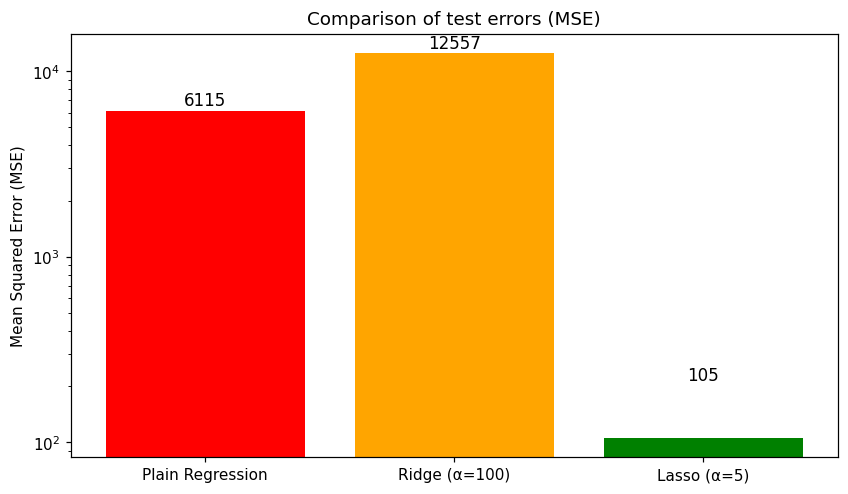

In [20]:
ridge_best = Ridge(alpha=100)
ridge_best.fit(X_train_sc, y_train)
mse_ridge_best = mean_squared_error(y_test, ridge_best.predict(X_test_sc))

models = ['Plain Regression', 'Ridge (α=100)', 'Lasso (α=5)']
errors = [mse_test, mse_ridge_best, mse_lasso]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, errors, color=['red', 'orange', 'green'])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 100, int(yval),
             ha='center', va='bottom', fontsize=11)

plt.title('Comparison of test errors (MSE)')
plt.ylabel('Mean Squared Error (MSE)')
plt.yscale('log')
plt.show()